In [1]:
# Core libraries
from collections import defaultdict
from itertools import combinations, product
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Clustering and statistical tools
from scipy.cluster.hierarchy import (
    dendrogram,
    linkage,
)
from scipy.stats import (
    kurtosis,
    skew,
)
from sklearn.cluster import (
    AgglomerativeClustering,
)
from sklearn.preprocessing import (
    StandardScaler,
)

# Reproducible random selection of AA combinations.
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

In [2]:
# Load the raw secondary-event data used for clustering.

#DATA_DIR = Path(".")
DATA_DIR = Path(
    "/Volumes/JAEONCHO/ADIC-AA/g_CD data"
)

SUB_EVENT_DIR = (
    DATA_DIR / "sub_events_g_CD"
)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

clustering_datasets = []

for sub_event_file in sorted(
    SUB_EVENT_DIR.glob("*.csv")
):
    aa_label = sub_event_file.name[0]
    recording_id = (
        sub_event_file.stem.removesuffix("_sub")
    )

    # Exclude the ADIC-only control.
    if aa_label == "0":
        continue

    sub_events = pd.read_csv(
        sub_event_file
    )

    required_column = (
        "sub_post_interaction_stdev"
    )

    if required_column not in sub_events.columns:
        raise KeyError(
            f"{required_column} was not found in "
            f"{sub_event_file.name}."
        )

    clustering_data = pd.DataFrame({
        "AA": aa_label,
        "sub_post_interaction_stdev":
            sub_events[required_column],
        "dataset_id": recording_id,
    })

    clustering_datasets.append(
        clustering_data
    )

if not clustering_datasets:
    raise ValueError(
        "No raw secondary-event data were found."
    )

df = pd.concat(
    clustering_datasets,
    ignore_index=True,
)

# Remove missing or nonfinite measurements.
df = df.dropna(
    subset=["sub_post_interaction_stdev"]
).copy()

df = df.loc[
    np.isfinite(
        df["sub_post_interaction_stdev"]
    )
].reset_index(drop=True)

print(
    f"Amino acids: "
    f"{df['AA'].nunique()}"
)

print(
    f"Raw secondary events: "
    f"{len(df):,}"
)

print(
    f"Recordings: "
    f"{df['dataset_id'].nunique():,}"
)

display(df.head())

Amino acids: 20
Raw secondary events: 113,597
Recordings: 228


,AA,sub_post_interaction_stdev,dataset_id
0,A,1.770020,A_g_CD_250528__0002
1,A,1.845297,A_g_CD_250528__0002
2,A,2.246309,A_g_CD_250528__0002
3,A,2.197266,A_g_CD_250528__0002
4,A,1.983643,A_g_CD_250528__0002


In [3]:
# Summarize the distribution of
# sub_post_interaction_stdev for each AA.

summary_records = []

for aa_label in sorted(
    df["AA"].unique()
):
    class_values = (
        df.loc[
            df["AA"] == aa_label,
            "sub_post_interaction_stdev",
        ]
        .to_numpy(dtype=float)
    )

    if len(class_values) < 4:
        raise ValueError(
            f"Insufficient observations for "
            f"{aa_label}: {len(class_values)}"
        )

    summary_records.append({
        "AA": aa_label,
        "mean": np.mean(class_values),
        "standard_deviation":
            np.std(
                class_values,
                ddof=0,
            ),
        "skewness":
            skew(
                class_values,
                bias=True,
            ),
        "kurtosis":
            kurtosis(
                class_values,
                bias=True,
            ),
        "number_of_events":
            len(class_values),
    })

class_summary = pd.DataFrame(
    summary_records
)

summary_feature_names = [
    "mean",
    "standard_deviation",
    "skewness",
    "kurtosis",
]

# Matrix used for hierarchical clustering.
clustering_matrix = (
    class_summary[
        summary_feature_names
    ]
    .to_numpy()
)

class_labels = (
    class_summary["AA"]
    .to_numpy()
)

if not np.isfinite(
    clustering_matrix
).all():
    raise ValueError(
        "Nonfinite values were detected in the "
        "AA-level summary features."
    )

class_summary.to_csv(
    OUTPUT_DIR
    / "AA_clustering_distribution_summary.csv",
    index=False,
)

display(class_summary)

,AA,mean,standard_deviation,skewness,kurtosis,number_of_events
0,A,1.682088,0.401915,-1.795963,6.996750,2801
1,C,1.449883,0.632235,-0.852806,0.318540,1204
2,D,1.626885,0.668114,-1.655760,1.623196,2615
3,E,1.616674,0.402557,-2.018157,6.602733,8387
4,F,1.919889,0.486303,-1.295689,4.867554,15047
5,G,1.594570,0.420475,-1.247148,5.451950,8533
6,H,1.766206,0.551172,-0.181397,2.443211,8988
7,I,2.631039,0.584959,-1.373486,5.737954,8156
8,K,1.548726,0.541771,-1.839118,2.886278,1703
9,L,2.051384,0.444290,-2.465613,9.652507,6138


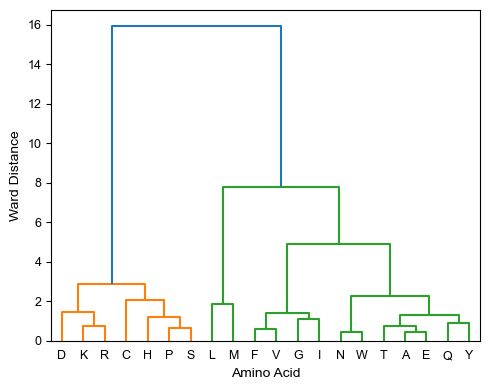

Cluster 0: ['A', 'E', 'N', 'Q', 'T', 'W', 'Y']
Cluster 1: ['C', 'H', 'P', 'S']
Cluster 2: ['L', 'M']
Cluster 3: ['F', 'G', 'I', 'V']
Cluster 4: ['D', 'K', 'R']


,AA,cluster
0,A,0
1,E,0
2,N,0
3,Q,0
4,T,0
5,W,0
6,Y,0
7,C,1
8,H,1
9,P,1


In [4]:
# Perform Ward hierarchical clustering using the
# four unscaled AA-level distribution summaries.

NUMBER_OF_CLUSTERS = 5

# Preserve the analysis performed in the archived code:
# clustering is applied to the original summary values,
# without StandardScaler transformation.
ward_linkage = linkage(
    clustering_matrix,
    method="ward",
)

agglomerative_model = AgglomerativeClustering(
    n_clusters=NUMBER_OF_CLUSTERS,
    linkage="ward",
)

raw_cluster_labels = (
    agglomerative_model.fit_predict(
        clustering_matrix
    )
)

# Cluster numbers are arbitrary. Use one established
# anchor AA from each cluster to retain the cluster IDs
# used by the downstream classifiers.
cluster_anchors = {
    "W": 0,
    "H": 1,
    "L": 2,
    "F": 3,
    "D": 4,
}

raw_to_canonical_cluster = {}

for anchor_aa, canonical_cluster in (
    cluster_anchors.items()
):
    anchor_position = np.where(
        class_labels == anchor_aa
    )[0]

    if len(anchor_position) != 1:
        raise ValueError(
            f"Anchor AA {anchor_aa} was not found "
            "exactly once."
        )

    raw_cluster = int(
        raw_cluster_labels[
            anchor_position[0]
        ]
    )

    if (
        raw_cluster
        in raw_to_canonical_cluster
        and raw_to_canonical_cluster[raw_cluster]
        != canonical_cluster
    ):
        raise ValueError(
            "Two anchor AAs were assigned to the same "
            "raw cluster."
        )

    raw_to_canonical_cluster[
        raw_cluster
    ] = canonical_cluster

if (
    len(raw_to_canonical_cluster)
    != NUMBER_OF_CLUSTERS
):
    raise ValueError(
        "The anchor AAs did not identify five distinct "
        "clusters."
    )

canonical_cluster_labels = np.array([
    raw_to_canonical_cluster[
        int(raw_cluster)
    ]
    for raw_cluster
    in raw_cluster_labels
])

cluster_assignments = pd.DataFrame({
    "AA": class_labels,
    "cluster":
        canonical_cluster_labels,
})

cluster_assignments = (
    cluster_assignments
    .sort_values(
        [
            "cluster",
            "AA",
        ]
    )
    .reset_index(drop=True)
)

cluster_assignments.to_csv(
    OUTPUT_DIR
    / "AA_cluster_assignments.csv",
    index=False,
)

# Display the dendrogram.
plt.rcParams["font.family"] = "Arial"

plt.figure(figsize=(5, 4))

dendrogram(
    ward_linkage,
    labels=class_labels,
    orientation="top",
)

plt.xlabel(
    "Amino Acid",
    fontsize=10,
    fontfamily="Arial",
)

plt.ylabel(
    "Ward Distance",
    fontsize=10,
    fontfamily="Arial",
)

plt.xticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.yticks(
    fontsize=9,
    fontfamily="Arial",
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR
    / "AA_hierarchical_clustering_dendrogram.png",
    dpi=600,
    bbox_inches="tight",
)

plt.show()

# Create dictionaries for downstream analysis.
clusters = defaultdict(list)

for aa_label, cluster_id in zip(
    class_labels,
    canonical_cluster_labels,
):
    clusters[int(cluster_id)].append(
        aa_label
    )

for cluster_id in clusters:
    clusters[cluster_id] = sorted(
        clusters[cluster_id]
    )

class_to_cluster = {
    aa_label: int(cluster_id)
    for aa_label, cluster_id
    in zip(
        class_labels,
        canonical_cluster_labels,
    )
}

for cluster_id in sorted(clusters):
    print(
        f"Cluster {cluster_id}: "
        f"{clusters[cluster_id]}"
    )

display(cluster_assignments)